# 01 · SVR–GARCH + CUSUM of squares — 알고리즘 단계별 재현
Lee, Kim & Lee (2020), *Entropy* 22(5) 578. 원문 Eq.(1)–(9), §2 Step 1–5, §3 CUSUM 을 `src/paper2020` 모듈로 한 단계씩 실행한다.

- 표기: **ASSUMPTION** = 원문에 없는 구현 선택, **DEVIATION** = 원문과 다른 선택 (`config/paper2020_runtime.yaml`).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'config' / 'paper2020_runtime.yaml').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

## 1. 데이터 생성 — GARCH(1,1) baseline ω=α=β=0.3, 길이 2n (n=500), 테스트 중앙에서 ω→1.0 변화
초기값·burn-in(1000)은 원문에 없음 → ASSUMPTION.

350 150 500


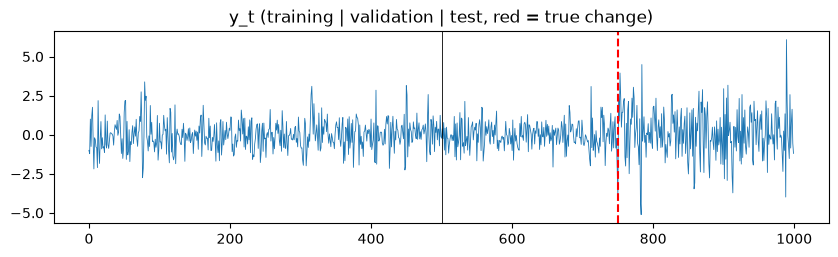

In [2]:
from paper2020.garch_dgp import simulate_dgp, ChangeSpec, DGPModel
from paper2020.runner import dgp_assumptions, MASTER_SEED
n = 500
base = {'omega': 0.3, 'alpha': 0.3, 'beta': 0.3}
sim = simulate_dgp(DGPModel.GARCH, base, length=2*n, assumptions=dgp_assumptions(DGPModel.GARCH), seed=MASTER_SEED,
                   change=ChangeSpec(n + n//2, DGPModel.GARCH, {**base, 'omega': 1.0}))
y = sim.observations
train, val, test = y[:int(0.7*n)], y[int(0.7*n):n], y[n:]
print(len(train), len(val), len(test))
fig, ax = plt.subplots(figsize=(10, 2.5)); ax.plot(y, lw=.6); ax.axvline(n, c='k', lw=.6); ax.axvline(n+n//2, c='r', ls='--'); ax.set_title('y_t (training | validation | test, red = true change)'); plt.show()

## 2. Step 2 — 변동성 proxy σ̃²_t = (1/m)Σ y²_{t-j+1}, m=5 (t<m 은 expanding mean)

In [3]:
from paper2020.volatility_proxy import moving_square_proxy, build_lagged_design, BoundaryPolicy
proxy = moving_square_proxy(train, m=5, boundary_policy=BoundaryPolicy.RESET)
assert np.isclose(proxy[0], train[0]**2) and np.isclose(proxy[10], np.mean(train[6:11]**2))
design = build_lagged_design(train, proxy, p=1, q=1, boundary_policy=BoundaryPolicy.RESET)
print('Eq.(9) x_t = (y_{t-1}^2, sigma~_{t-1}^2):', design.X[:3], 'target sigma~_t^2:', design.target[:3])
# 누출 검사: 행 t 의 feature 는 t-1 까지만 사용
assert np.allclose(design.X[:, 0], train[design.target_indices - 1]**2)

Eq.(9) x_t = (y_{t-1}^2, sigma~_{t-1}^2): [[1.0027 1.0027]
 [1.4754 1.239 ]
 [0.9978 1.1586]] target sigma~_t^2: [1.239  1.1586 1.0107]


## 3. Eq.(2)–(8) — ε-insensitive SVR, RBF 커널 exp(−‖x−y‖²/(2γ²)) ↔ sklearn `gamma = 1/(2γ²)`

In [4]:
from sklearn.metrics.pairwise import rbf_kernel
from paper2020.svr_garch import paper_gamma_to_sklearn
X = design.X[:4]; g2 = 0.5
paper_K = np.exp(-((X[:, None] - X[None]) ** 2).sum(-1) / (2 * g2))
assert np.allclose(paper_K, rbf_kernel(X, gamma=paper_gamma_to_sklearn(g2)))
print('kernel mapping OK')

kernel mapping OK


## 4. Step 1·4·5 — grid search (C∈{1,10,100}, γ²∈{0.1,0.5,1}, ε∈{0.1,0.5,1}; 원문은 범위만 제시 → ASSUMPTION), validation MAE, 결합 재적합

In [5]:
from paper2020.runner import make_spec
from paper2020.svr_garch import select_and_refit, forecast_test_variance, VariancePredictionPolicy
spec = make_spec('full', clip=True)
fit = select_and_refit(train, val, parameter_grid=spec.parameter_grid, fit_policy=spec.fit_policy, m=5, p=1, q=1,
    validation_proxy_boundary=spec.validation_proxy_boundary, validation_lag_boundary=spec.validation_lag_boundary,
    validation_variance_policy=spec.validation_variance_policy, variance_floor=spec.variance_floor, tie_policy=spec.selection_tie_policy)
scores = pd.DataFrame([{**vars(s.parameters), 'MAE': s.mae} for s in fit.scores]).sort_values('MAE')
print('selected:', fit.best_parameters); scores.head()

selected: SVRParameters(C=10.0, paper_gamma_squared=0.5, epsilon=0.1)


,C,paper_gamma_squared,epsilon,MAE
12,10.0,0.5,0.1,0.264709
15,10.0,1.0,0.1,0.265519
6,1.0,1.0,0.1,0.266291
3,1.0,0.5,0.1,0.269017
24,100.0,1.0,0.1,0.276389


## 5. 테스트 구간 조건부 분산과 표준화 잔차 ê_t = y_t/σ̂_t
테스트 구간에서 Eq.(9) 의 분산 lag 를 무엇으로 채울지는 원문에 명시가 없다. primary = 관측 proxy(OBSERVED_PROXY), 민감도 = 재귀 예측(RECURSIVE_PREDICTION).

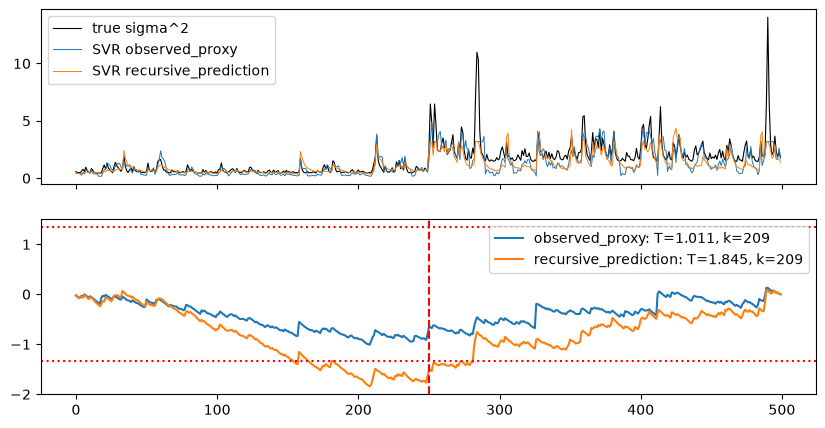

{'observed_proxy': (1.0109, False, 209),
 'recursive_prediction': (1.8446, True, 209)}

In [6]:
from paper2020.svr_garch import TestVarianceInputPolicy
from paper2020.cusum import standardized_residuals, NonPositiveVariancePolicy, cusum_squares_test, ArgmaxTiePolicy, DegenerateTauPolicy
out = {}
for pol in (TestVarianceInputPolicy.OBSERVED_PROXY, TestVarianceInputPolicy.RECURSIVE_PREDICTION):
    fc = forecast_test_variance(fit, test, m=5, p=1, q=1, input_policy=pol, proxy_boundary=BoundaryPolicy.CARRY,
                                lag_boundary=BoundaryPolicy.CARRY, prediction_policy=VariancePredictionPolicy.RAW, variance_floor=None)
    e = standardized_residuals(test, fc.variance, nonpositive_policy=NonPositiveVariancePolicy.CLIP, variance_floor=spec.variance_floor)
    out[pol.value] = (fc.variance, e, cusum_squares_test(e, tie_policy=ArgmaxTiePolicy.FIRST, degenerate_tau_policy=DegenerateTauPolicy.RAISE))
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(sim.variance[n:], c='k', lw=.8, label='true sigma^2')
for k, (v, e, cu) in out.items():
    ax[0].plot(v, lw=.7, label=f'SVR {k}'); ax[1].plot(cu.centered_path / (np.sqrt(len(e)) * np.sqrt(cu.tau_squared)), label=f'{k}: T={cu.statistic:.3f}, k={cu.change_index_one_based}')
ax[1].axhline(1.3397, c='r', ls=':'); ax[1].axhline(-1.3397, c='r', ls=':'); ax[1].axvline(n//2, c='r', ls='--')
ax[0].legend(); ax[1].legend(); plt.show()
{k: (round(cu.statistic, 4), cu.reject, cu.change_index_one_based) for k, (_, _, cu) in out.items()}

## 6. §3 CUSUM golden test — ê=(1,1,1,3) → D=(−2,−4,−6,0), τ²=12, T=√3/2, k̂=3, 비기각 (c=1.3397)

In [7]:
cu = cusum_squares_test([1., 1., 1., 3.], tie_policy=ArgmaxTiePolicy.FIRST, degenerate_tau_policy=DegenerateTauPolicy.RAISE)
assert np.allclose(cu.centered_path, [-2, -4, -6, 0]) and np.isclose(cu.tau_squared, 12) and np.isclose(cu.statistic, np.sqrt(3)/2)
assert cu.change_index_one_based == 3 and not cu.reject
print('golden OK', cu.statistic)

golden OK 0.8660254037844387


## 7. 다섯 GARCH 생성모형 (원문 p.8) baseline 표본 경로

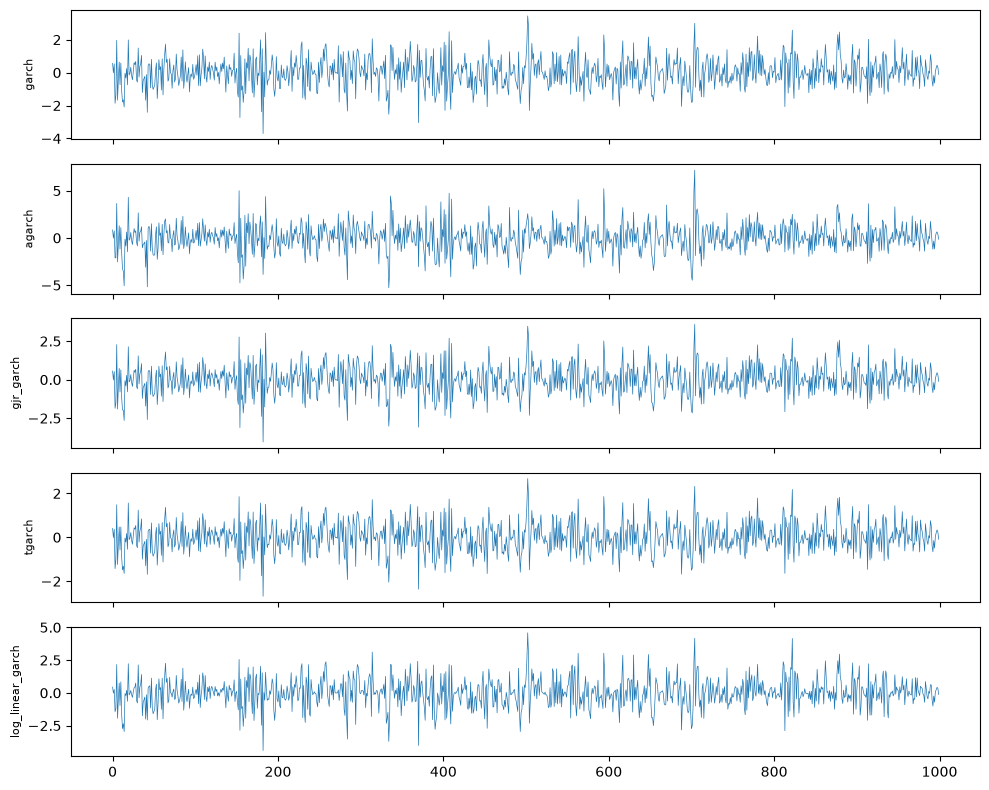

In [8]:
from paper2020.simulation import TABLE_CASES
fig, axes = plt.subplots(5, 1, figsize=(10, 8), sharex=True)
for ax, case in zip(axes, [c for c in TABLE_CASES if c.is_size]):
    r = simulate_dgp(case.baseline_model, case.baseline_parameters, length=1000, assumptions=dgp_assumptions(case.baseline_model), seed=1)
    ax.plot(r.observations, lw=.5); ax.set_ylabel(case.baseline_model.value, fontsize=8)
plt.tight_layout(); plt.show()

## 8. (감사 추가) 테스트 구간 분산 정책 A / B / C — `reports/TEST_TIME_RECURSION_AUDIT.md`
- **A** σ̂²_t = ĝ(y²_{t−1}, σ̃²_{t−1}) — 원문 Step 3 식을 테스트에 문자 그대로 연장 (`ASSUMPTION`)
- **B** σ̂²_t = ĝ(y²_{t−1}, σ̂²_{t−1}) — §3 모수 GARCH 재귀와 같은 구조 (`SENSITIVITY`)
- **C** ĝ 자체를 반복 재적합 — Remark 2 가 기각, 미구현. B ≠ C
원문은 테스트 구간 정책을 명시하지 않는다 → `UNRESOLVED`. 아래는 두 정책이 미래 관측을 쓰지 않음을 같은 코드 경로로 보이는 경계 검사다.

In [9]:
fcs = {}
te2 = test.copy(); k = 100; te2[k:] = te2[k:] * 5 + 2
for pol in (TestVarianceInputPolicy.OBSERVED_PROXY, TestVarianceInputPolicy.RECURSIVE_PREDICTION):
    v0 = forecast_test_variance(fit, test, m=5, p=1, q=1, input_policy=pol, proxy_boundary=BoundaryPolicy.CARRY, lag_boundary=BoundaryPolicy.CARRY, prediction_policy=VariancePredictionPolicy.RAW, variance_floor=None).variance
    v1 = forecast_test_variance(fit, te2, m=5, p=1, q=1, input_policy=pol, proxy_boundary=BoundaryPolicy.CARRY, lag_boundary=BoundaryPolicy.CARRY, prediction_policy=VariancePredictionPolicy.RAW, variance_floor=None).variance
    assert np.array_equal(v0[:k+1], v1[:k+1]) and not np.array_equal(v0[k+1:], v1[k+1:])
    print(pol.value, ': y_j (j>=100) 변경 -> sigma_hat^2_0..100 불변 OK')

observed_proxy : y_j (j>=100) 변경 -> sigma_hat^2_0..100 불변 OK


recursive_prediction : y_j (j>=100) 변경 -> sigma_hat^2_0..100 불변 OK


### A 가 변화를 흡수하는 메커니즘 — ê² 의 long-run variance / τ̂²
A 에서 1 보다 작으면 CUSUM 분모가 실제 장기분산을 과대평가 → T̂ 축소 → size 과소.

In [10]:
from paper2020.ablation import _lrv_ratio
for k_, (v, e, cu) in out.items():
    print(f'{k_:22s} LRV(e^2)/tau^2 = {_lrv_ratio(e):.3f}   T = {cu.statistic:.3f}')

observed_proxy         LRV(e^2)/tau^2 = 0.786   T = 1.011
recursive_prediction   LRV(e^2)/tau^2 = 1.285   T = 1.845
